In [1]:
import pandas as pd
import numpy as np
import re

# Load the spam dataset using latin-1 encoding as discussed
df = pd.read_csv("../data/spam.csv", encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "text"]

# Clean missing and duplicate values
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["target"] = (df["label"] == "spam").astype(int)

print("Dataset shape:", df.shape)
print("\nLabel counts:\n", df["label"].value_counts())

Dataset shape: (5169, 3)

Label counts:
 label
ham     4516
spam     653
Name: count, dtype: int64


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

url_pat = re.compile(r"(https?://\S+|www\.\S+|\b[a-z0-9-]+\.(?:com|net|org|info|biz|co\.uk)\S*)", re.I)

df["char_len"]    = df["text"].str.len()
df["word_len"]    = df["text"].str.split().str.len()
df["num_links"]   = df["text"].apply(lambda t: len(url_pat.findall(t)))
df["num_special"] = df["text"].apply(lambda t: len(re.findall(r"[$!%£€&*]", t)))
df["num_digits"]  = df["text"].str.count(r"\d")

print(df.groupby("label")[["char_len","num_links","num_special","num_digits"]].mean())

         char_len  num_links  num_special  num_digits
label                                                
ham     70.459256   0.002879     0.365146    0.290301
spam   137.891271   0.196018     1.523737   15.447167


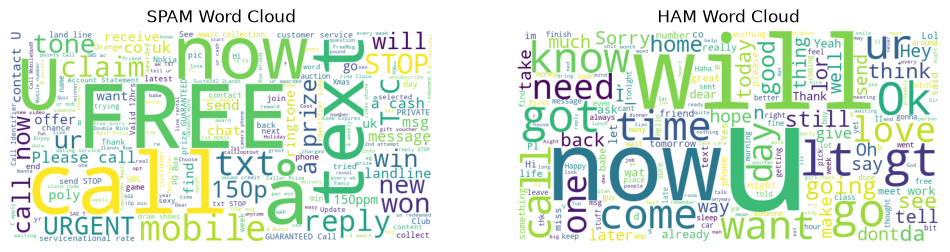

In [3]:
from wordcloud import WordCloud

plt.figure(figsize=(12, 6))
for i, lbl in enumerate(["spam", "ham"], 1):
    plt.subplot(1, 2, i)
    txt = " ".join(df[df.label == lbl]["text"])
    plt.imshow(WordCloud(width=800, height=400, background_color="white").generate(txt))
    plt.axis("off")
    plt.title(f"{lbl.upper()} Word Cloud")
plt.show()

In [4]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))

from src.preprocess_text import clean_text
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score
import joblib

df["clean"] = df["text"].apply(clean_text)
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"], test_size=0.2, stratify=df["target"], random_state=42
)

models = {
    "NaiveBayes":   MultinomialNB(),
    "LinearSVM":    LinearSVC(class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2)), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = (f1_score(y_test, pred), pipe)
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=["ham","spam"]))

# Save the best model
best = max(results, key=lambda k: results[k][0])
os.makedirs("../models", exist_ok=True)
joblib.dump(results[best][1], "../models/spam_model.pkl")
print(f"\nSuccessfully saved best model ({best}) to models/spam_model.pkl!")


=== NaiveBayes ===
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       1.00      0.83      0.91       131

    accuracy                           0.98      1034
   macro avg       0.99      0.92      0.95      1034
weighted avg       0.98      0.98      0.98      1034


=== LinearSVM ===
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.94      0.94      0.94       131

    accuracy                           0.98      1034
   macro avg       0.97      0.97      0.97      1034
weighted avg       0.98      0.98      0.98      1034


=== RandomForest ===
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.91      0.93       131

    accuracy                           0.98      1034
   macro avg       0.97      0.95      0.96      1034
weighted avg 